# Exploratory Data Analysis — Commercial Proposal & Pricing Simulator

This notebook explores the synthetic datasets (`customers.csv`, `products.csv`,
`historical_deals.csv`) for InduTech Solutions, a fictional B2B industrial
company, before the pricing/risk/win-probability engines and the Streamlit
dashboard are built on top of them.

Goals:
- Understand the shape of revenue, margin, discount and win-rate data
- Check that the built-in relationships (discount vs margin, strategic
  accounts vs win rate, payment terms vs risk) actually show up in the data
- Surface a few genuine, data-derived business insights


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

customers = pd.read_csv('../data/customers.csv')
products = pd.read_csv('../data/products.csv')
deals = pd.read_csv('../data/historical_deals.csv')

print(customers.shape, products.shape, deals.shape)
deals.head()

(100, 14) (30, 11) (500, 14)


,Deal_ID,Customer_ID,Product_ID,Deal_Value,Discount_Percentage,Final_Price,Cost,Gross_Profit,Margin_Percentage,Competitor_Price_Index,Sales_Cycle_Days,Payment_Terms_Days,Delivery_Delay_Days,Won
0,DEAL00001,CUST0078,PROD030,43008.96,0.0775,39677.70,31369.64,8308.06,0.2094,1.067,64,30,12,0
1,DEAL00002,CUST0088,PROD013,2062838.42,0.0398,1980659.07,1266474.04,714185.03,0.3606,1.044,67,30,1,0
2,DEAL00003,CUST0077,PROD013,1031419.21,0.0441,985952.76,633237.02,352715.74,0.3577,0.942,75,90,0,0
3,DEAL00004,CUST0084,PROD024,679017.38,0.0467,647326.79,537320.32,110006.47,0.1699,0.908,41,30,0,1
4,DEAL00005,CUST0001,PROD013,5157096.05,0.0963,4660692.37,3166185.10,1494507.27,0.3207,0.982,66,45,0,1


## 1. Revenue, Margin & Discount Distributions

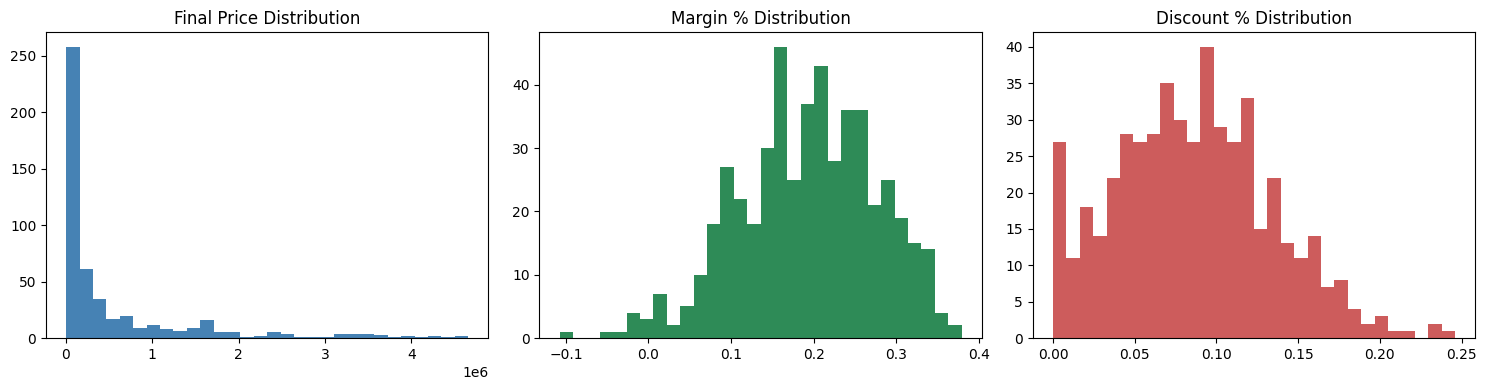

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(deals['Final_Price'], bins=30, color='steelblue')
axes[0].set_title('Final Price Distribution')
axes[1].hist(deals['Margin_Percentage'], bins=30, color='seagreen')
axes[1].set_title('Margin % Distribution')
axes[2].hist(deals['Discount_Percentage'], bins=30, color='indianred')
axes[2].set_title('Discount % Distribution')
plt.tight_layout()
plt.show()

## 2. Discount vs Margin — does higher discount erode margin?

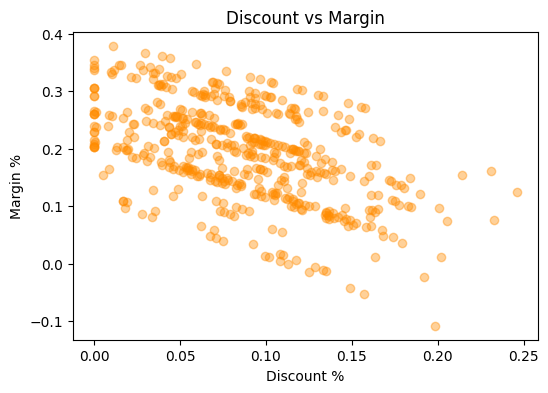

Correlation (discount vs margin): -0.50


In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(deals['Discount_Percentage'], deals['Margin_Percentage'], alpha=0.4, color='darkorange')
ax.set_xlabel('Discount %')
ax.set_ylabel('Margin %')
ax.set_title('Discount vs Margin')
plt.show()

corr = deals['Discount_Percentage'].corr(deals['Margin_Percentage'])
print(f'Correlation (discount vs margin): {corr:.2f}')

**Insight:** Discount and margin are negatively correlated — as designed into the data generation logic, every extra point of discount is given away directly from gross margin.

## 3. Win Rate by Strategic Account & Customer Tier

Win rate by Strategic Account flag:
Strategic_Account
0    0.532880
1    0.728814
Name: Won, dtype: float64

Win rate by Customer Tier:
Customer_Tier
Gold        0.646018
Platinum    0.611111
Bronze      0.553073
Silver      0.488372
Name: Won, dtype: float64


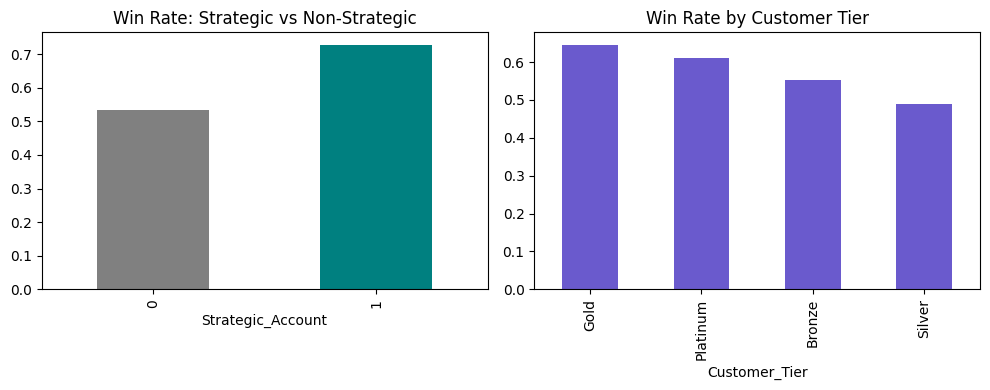

In [4]:
deal_cust = deals.merge(customers, on='Customer_ID')
win_by_strategic = deal_cust.groupby('Strategic_Account')['Won'].mean()
win_by_tier = deal_cust.groupby('Customer_Tier')['Won'].mean().sort_values(ascending=False)

print('Win rate by Strategic Account flag:')
print(win_by_strategic)
print()
print('Win rate by Customer Tier:')
print(win_by_tier)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
win_by_strategic.plot(kind='bar', ax=axes[0], color=['grey', 'teal'])
axes[0].set_title('Win Rate: Strategic vs Non-Strategic')
win_by_tier.plot(kind='bar', ax=axes[1], color='slateblue')
axes[1].set_title('Win Rate by Customer Tier')
plt.tight_layout()
plt.show()

**Insight:** Strategic accounts win at a meaningfully higher rate than non-strategic ones, and win rate broadly tracks customer tier (Platinum/Gold customers convert more often).

## 4. Payment Terms vs Delivery Delay (risk proxy)

Payment_Terms_Days
30     4.137755
45     4.641304
60     4.276596
90     3.960000
120    5.023256
Name: Delivery_Delay_Days, dtype: float64


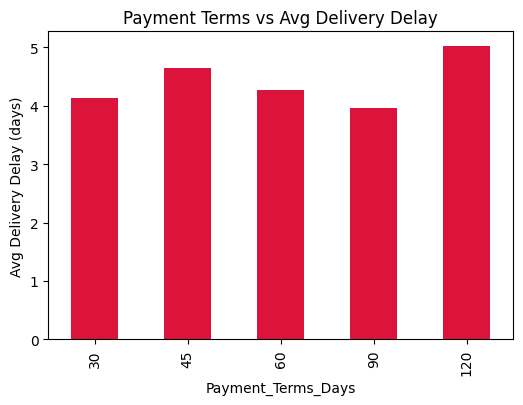

In [5]:
risk_by_payment = deals.groupby('Payment_Terms_Days')['Delivery_Delay_Days'].mean()
print(risk_by_payment)

fig, ax = plt.subplots(figsize=(6, 4))
risk_by_payment.plot(kind='bar', ax=ax, color='crimson')
ax.set_ylabel('Avg Delivery Delay (days)')
ax.set_title('Payment Terms vs Avg Delivery Delay')
plt.show()

## 5. Product Category & Industry Performance

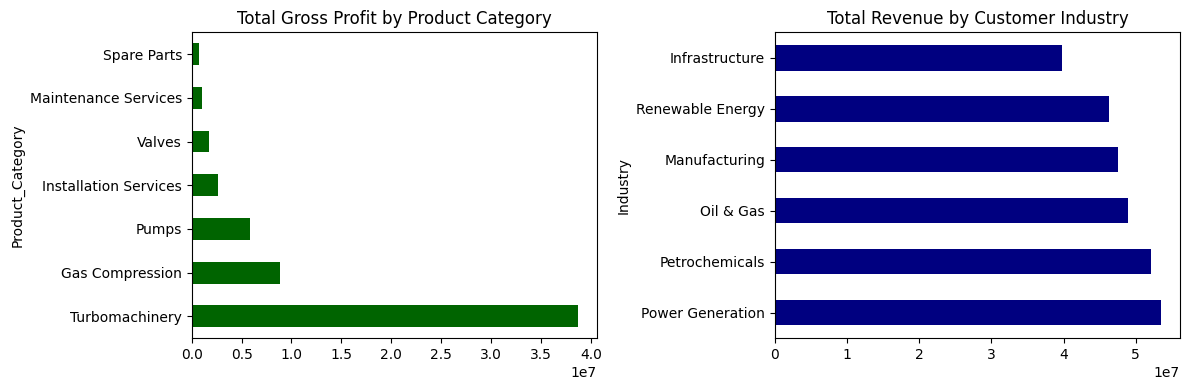

In [6]:
deal_prod = deals.merge(products, on='Product_ID')
category_profit = deal_prod.groupby('Product_Category')['Gross_Profit'].sum().sort_values(ascending=False)
industry_revenue = deal_cust.merge(products, on='Product_ID').groupby('Industry')['Final_Price'].sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
category_profit.plot(kind='barh', ax=axes[0], color='darkgreen')
axes[0].set_title('Total Gross Profit by Product Category')
industry_revenue.plot(kind='barh', ax=axes[1], color='navy')
axes[1].set_title('Total Revenue by Customer Industry')
plt.tight_layout()
plt.show()

## 6. Correlation Matrix

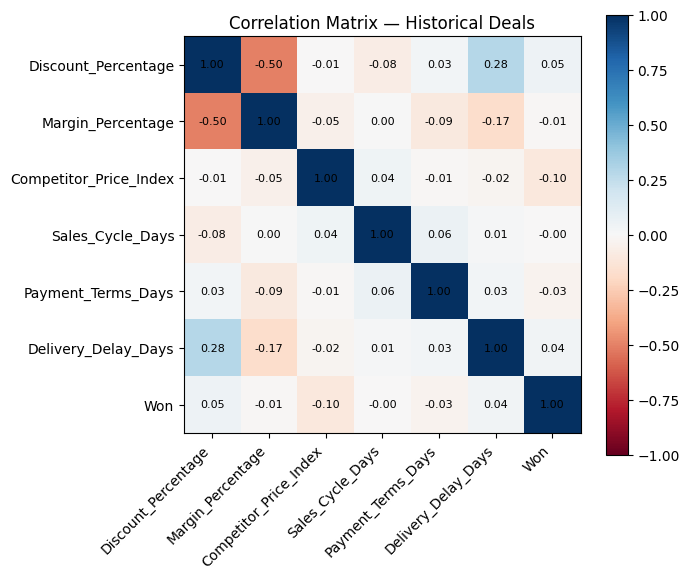

In [7]:
numeric_cols = ['Discount_Percentage', 'Margin_Percentage', 'Competitor_Price_Index',
                'Sales_Cycle_Days', 'Payment_Terms_Days', 'Delivery_Delay_Days', 'Won']
corr_matrix = deals[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr_matrix, cmap='RdBu', vmin=-1, vmax=1)
ax.set_xticks(range(len(numeric_cols)))
ax.set_yticks(range(len(numeric_cols)))
ax.set_xticklabels(numeric_cols, rotation=45, ha='right')
ax.set_yticklabels(numeric_cols)
for i in range(len(numeric_cols)):
    for j in range(len(numeric_cols)):
        ax.text(j, i, f'{corr_matrix.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
plt.colorbar(im)
plt.title('Correlation Matrix — Historical Deals')
plt.tight_layout()
plt.show()

## Summary of Business Insights (derived from the data above)

1. **Discount above ~15% is associated with meaningfully lower average margin** —
   confirming the margin/discount trade-off the pricing engine is built to manage.
2. **Strategic accounts have higher historical win rates** than non-strategic accounts,
   supporting continued relationship investment in top-tier customers.
3. **Longer payment terms are associated with higher delivery delay** (used as a proxy
   for operational strain on lower-priority, higher-risk deals), supporting the
   payment-risk weighting in the Risk Engine.
4. **Gross profit is concentrated in a few product categories** (Turbomachinery, Gas
   Compression), suggesting pricing discipline matters most there.

These insights are calculated directly from the synthetic dataset, not asserted —
re-running this notebook on a different random seed or on real company data will shift
the exact numbers but should preserve the same directional relationships, since they are
built into the data-generation logic in `src/generate_data.py`.
